In [1]:
from pathlib import Path
import pandas as pd
from google.cloud import bigquery

PROJECT_ID = "radar-economia-br"
client = bigquery.Client(project=PROJECT_ID, location="US")

df = client.query(f"""
    SELECT * FROM `{PROJECT_ID}.economia_br.vw_base_mensal` ORDER BY mes
""").to_dataframe()

df["mes"] = pd.to_datetime(df["mes"])
df = df.set_index("mes")

Path("../data/processed").mkdir(parents=True, exist_ok=True)
df.to_csv("../data/processed/base_mensal.csv")

print(df.shape)
df.tail()

/Users/vidigal/Documents/radar-economia-br/.venv/lib/python3.14/site-packages/google/cloud/bigquery/table.py:2122: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


(201, 10)


,ipca_mensal,ipca_12m,selic_media,dolar_medio,dolar_fim_mes,desemprego,ibc_br,dolar_var_pct,ibc_br_var_12m,juro_real
mes,,,,,,,,,,
2026-05-01 00:00:00+00:00,0.58,4.724907,14.500000,4.983700,5.0569,5.6,109.79468,-0.98,1.12,9.33
2026-06-01 00:00:00+00:00,0.16,4.641328,14.391667,5.127571,5.1766,5.4,110.18456,2.89,2.59,9.32
2026-07-01 00:00:00+00:00,0.07,4.443025,14.250000,5.113948,5.0773,5.3,114.48992,-0.27,1.14,9.39
2026-08-01 00:00:00+00:00,-0.32,4.223453,14.040323,5.153162,5.1816,5.3,111.71919,0.77,1.21,9.42
2026-09-01 00:00:00+00:00,0.82,4.576120,13.883333,5.144724,5.1809,NaN,NaN,-0.16,NaN,8.90


In [2]:
# diagnóstico rápido de qualidade
df.info()
df.describe().round(2)
df.isna().sum()

<class 'pandas.DataFrame'>
DatetimeIndex: 201 entries, 2010-01-01 00:00:00+00:00 to 2026-09-01 00:00:00+00:00
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ipca_mensal     201 non-null    float64
 1   ipca_12m        190 non-null    float64
 2   selic_media     201 non-null    float64
 3   dolar_medio     201 non-null    float64
 4   dolar_fim_mes   201 non-null    float64
 5   desemprego      174 non-null    float64
 6   ibc_br          200 non-null    float64
 7   dolar_var_pct   200 non-null    float64
 8   ibc_br_var_12m  188 non-null    float64
 9   juro_real       190 non-null    float64
dtypes: float64(10)
memory usage: 17.3 KB


ipca_mensal        0
ipca_12m          11
selic_media        0
dolar_medio        0
dolar_fim_mes      0
desemprego        27
ibc_br             1
dolar_var_pct      1
ibc_br_var_12m    13
juro_real         11
dtype: int64

Matplotlib is building the font cache; this may take a moment.


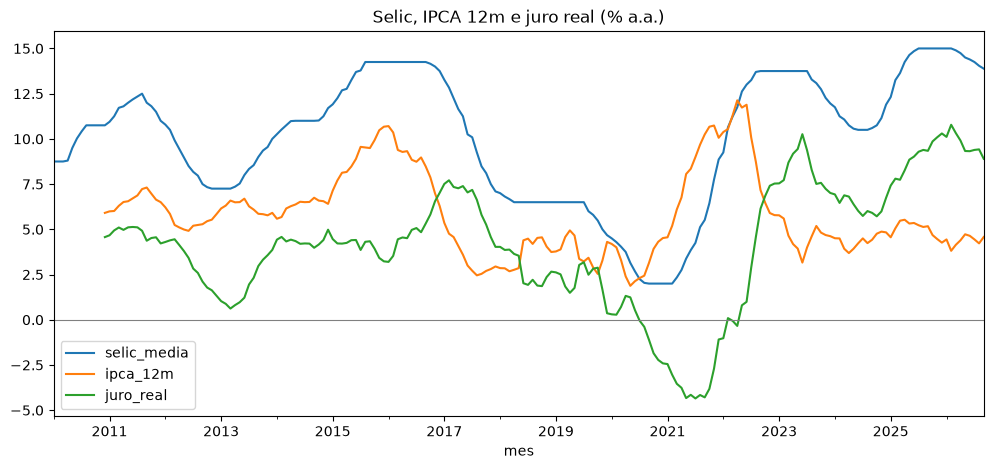

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
df[["selic_media", "ipca_12m", "juro_real"]].plot(ax=ax)
ax.set_title("Selic, IPCA 12m e juro real (% a.a.)")
ax.axhline(0, color="gray", lw=0.8)
plt.show()